In [1]:
%pip install pandas matplotlib scikit-learn joblib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from pathlib import Path

# Project folders
PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

DATA_PATH = PROJECT_DIR / "data" / "cleaned_charging_data.csv"
MODEL_PATH = PROJECT_DIR / "models" / "best_regression_model.joblib"

# Load data and model
df = pd.read_csv(DATA_PATH)
model = joblib.load(MODEL_PATH)

print("Dataset shape:", df.shape)
print("Regression model loaded successfully!")

# Check the model's pipeline steps
print("\nModel structure:")
print(model)

Dataset shape: (72843, 19)
Regression model loaded successfully!

Model structure:
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['ChargerCompany',
                                                   'ChargerType', 'Hour', 'Day',
                                                   'Month', 'DayOfWeek',
                                                   'IsWeekend']),
                                                 ('categorical',
                                                  Pipeline(steps=[('imputer',
                                              

In [3]:
import numpy as np

# Find the final estimator if the model is a pipeline
estimator = model
if hasattr(model, "steps"):
    estimator = model.steps[-1][1]

if hasattr(estimator, "feature_importances_"):
    importance = estimator.feature_importances_
    print("Using tree-based feature importance.")

elif hasattr(estimator, "coef_"):
    importance = np.ravel(estimator.coef_)
    importance = np.abs(importance)
    print("Using absolute regression coefficients.")

else:
    importance = None
    print(
        "This model does not expose feature importance or coefficients. "
        "We can use permutation importance instead."
    )

if importance is not None:
    if hasattr(model, "feature_names_in_"):
        feature_names = list(model.feature_names_in_)
    elif hasattr(estimator, "feature_names_in_"):
        feature_names = list(estimator.feature_names_in_)
    else:
        feature_names = None

    if feature_names is not None and len(feature_names) == len(importance):
        importance_df = pd.DataFrame({
            "Feature": feature_names,
            "Importance": importance
        }).sort_values("Importance", ascending=False)

        display(importance_df)

        plt.figure(figsize=(10, 6))
        plt.barh(
            importance_df["Feature"][::-1],
            importance_df["Importance"][::-1]
        )
        plt.title("Regression Model: Feature Importance")
        plt.xlabel("Importance (absolute coefficient or model importance)")
        plt.tight_layout()
        plt.show()
    else:
        print("Feature names could not be matched automatically.")
        print("Please share the model structure printed in the second cell.")

Using absolute regression coefficients.
Feature names could not be matched automatically.
Please share the model structure printed in the second cell.


Number of processed feature names: 25
Number of importance values: 25

Top 15 features:


,Feature,Importance
0,TimeOfDay_Night,8.835841
1,Location_bus garage,8.631298
2,Location_accommodation,8.499166
3,TimeOfDay_Afternoon,5.321076
4,Location_camping,5.233986
5,Location_hotel,4.310460
6,Location_market,3.412374
7,Location_public parking lot,3.143386
8,Location_sightseeing,3.105672
9,ChargerType,2.573312


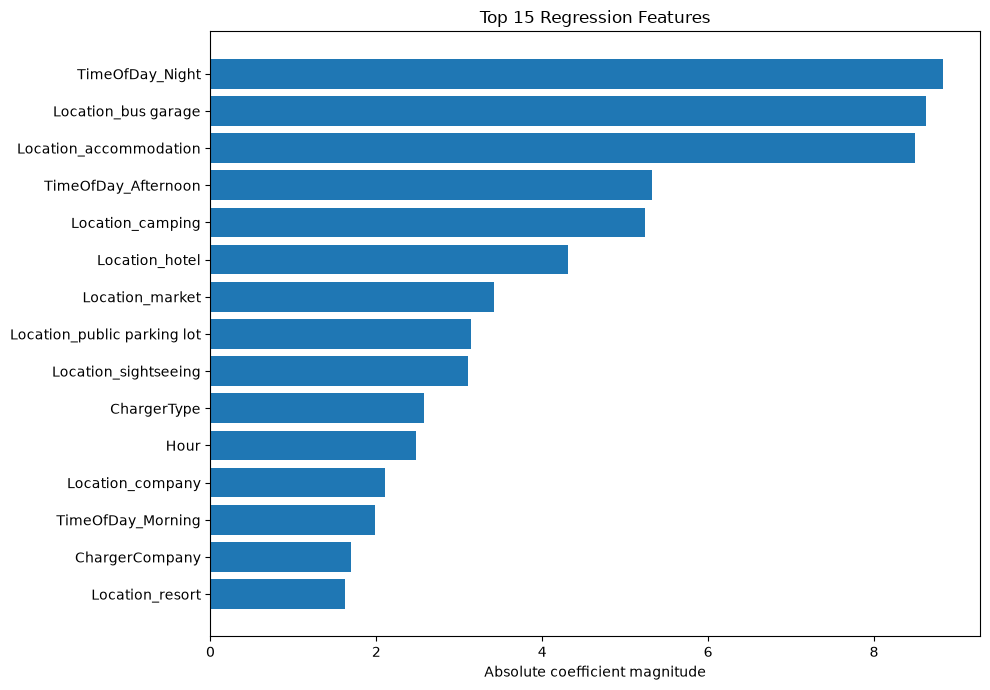


Saved feature importance to: c:\Users\Shyamsekar\OneDrive\Desktop\EV_Charging_Demand_Project\models\regression_feature_importance.csv


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Access the preprocessing pipeline and trained estimator
preprocessor = model.named_steps["preprocessor"]
estimator = model.steps[-1][1]

# Get feature names after preprocessing
feature_names = preprocessor.get_feature_names_out()

# Get absolute regression coefficients
if hasattr(estimator, "coef_"):
    importance = np.abs(np.ravel(estimator.coef_))
elif hasattr(estimator, "feature_importances_"):
    importance = estimator.feature_importances_
else:
    raise ValueError("The model does not expose coefficients or feature importance.")

# Check that names and values match
print("Number of processed feature names:", len(feature_names))
print("Number of importance values:", len(importance))

# Create results table
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
})

# Clean up feature names
importance_df["Feature"] = (
    importance_df["Feature"]
    .str.replace("numeric__", "", regex=False)
    .str.replace("categorical__", "", regex=False)
)

importance_df = importance_df.sort_values(
    "Importance", ascending=False
).reset_index(drop=True)

print("\nTop 15 features:")
display(importance_df.head(15))

# Plot top 15
top15 = importance_df.head(15).sort_values("Importance")

plt.figure(figsize=(10, 7))
plt.barh(top15["Feature"], top15["Importance"])
plt.title("Top 15 Regression Features")
plt.xlabel("Absolute coefficient magnitude")
plt.tight_layout()
plt.show()

# Save results
output_path = PROJECT_DIR / "models" / "regression_feature_importance.csv"
importance_df.to_csv(output_path, index=False)

print("\nSaved feature importance to:", output_path)